In [1]:
# --- PARAMÈTRES (toujours en tête du notebook) ---------------------------
CHEMIN_DONNEES = "portefeuille_vie.csv"
DATE_REF = "2025-01-01"     # début de la période d'observation (rachat_12m = rachat sur l'exercice 2025)
SEUIL_EFFECTIF = 100        # en dessous, un taux par segment est jugé peu fiable

# --- IMPORTS --------------------------------------------------------------
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)


# --- OUTIL D'AUTO-CONTRÔLE (ne pas modifier) ------------------------------
def verifier(libelle, test):
    """Affiche ✅ ou ❌ selon le résultat de `test` (une fonction sans argument)."""
    try:
        ok = bool(test())
    except Exception:
        ok = False
    print(("✅ " if ok else "❌ ") + libelle + ("" if ok else "   → à compléter ou à revoir"))

Python 3.14.6 | pandas 3.0.3 | numpy 2.4.6


---
# Atelier D — Visualiser : une figure se lit comme une preuve (≈ 15 min)
*Rappel théorique : le réflexe matplotlib — axes nommés avec unités, moyenne de référence tracée, période et source en note de page (slides « Le réflexe matplotlib » et son mini-test).*

### D1 · Le taux de rachat par tranche d'âge, figure « conforme »
Construisez la figure du profil en U avec **les quatre règles** :
1. axes nommés avec unités · 2. moyenne de référence tracée et étiquetée · 3. titre qui énonce le message · 4. période et source en note de page.
<details><summary>💡 Indice</summary><code>ax.set_xlabel("...")</code>, <code>ax.set_ylabel("...")</code>, <code>ax.axhline(valeur, linestyle="--")</code> pour la moyenne. Les taux sont en proportion : multipliez par 100 pour afficher des %.</details>

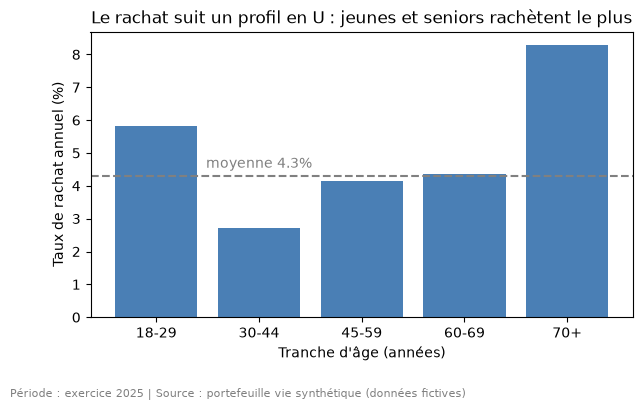

In [25]:
donnees = taux_age.drop("Non renseigné", errors="ignore")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(donnees.index.astype(str), donnees.taux_rachat * 100, color="#4a7fb5")

ax.set_xlabel("Tranche d'âge (années)")
ax.set_ylabel("Taux de rachat annuel (%)")
ax.set_title("Le rachat suit un profil en U : jeunes et seniors rachètent le plus")
ax.axhline(taux_global * 100, linestyle="--", color="gray")
ax.text(1, taux_global * 100 + 0.25, f"moyenne {taux_global:.1%}", color="gray", ha="center")

fig.text(0.01, 0.01, "Période : exercice 2025 | Source : portefeuille vie synthétique (données fictives)", fontsize=8, color="gray")
fig.subplots_adjust(bottom=0.2)
plt.show()

### D2 ·  Taux **et** effectif sur la même figure
Un taux sans son effectif est un taux sans contexte. Tracez le taux de rachat par génération (ligne) et l'effectif (barres grises, axe de droite).
<details><summary>💡 Indice</summary><code>ax2 = ax.twinx()</code> crée un second axe vertical qui partage l'axe horizontal. Dessinez les barres <b>avant</b> la ligne pour que la ligne reste visible.</details>

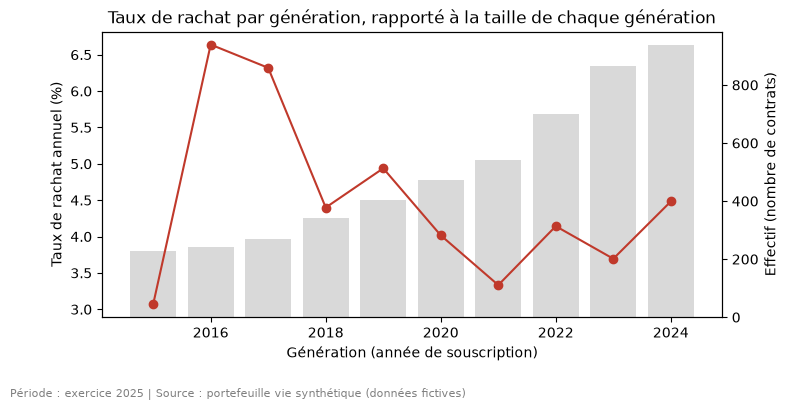

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax2 = ax.twinx()

ax2.bar(taux_gen.index, taux_gen.effectif, color="#d9d9d9")
ax2.set_ylabel("Effectif (nombre de contrats)")

ax.set_zorder(ax2.get_zorder() + 1)       # la ligne passe devant les barres
ax.patch.set_visible(False)
ax.plot(taux_gen.index, taux_gen.taux_rachat * 100, marker="o", color="#c0392b")
ax.set_xlabel("Génération (année de souscription)")
ax.set_ylabel("Taux de rachat annuel (%)")
ax.set_title("Taux de rachat par génération, rapporté à la taille de chaque génération")

fig.text(0.01, 0.01, "Période : exercice 2025 | Source : portefeuille vie synthétique (données fictives)", fontsize=8, color="gray")
fig.subplots_adjust(bottom=0.2)
plt.show()

### D3 ·  Afficher l'incertitude
Reprenez D1 en ajoutant les **barres d'erreur** (IC à 95 % calculés en C7) et l'effectif `n = …` au-dessus de chaque barre. Cette figure est celle qu'un validateur indépendant vous demandera.
<details><summary>💡 Indice</summary><code>ax.bar(x, hauteurs, yerr=erreurs, capsize=4)</code> ajoute les barres d'erreur (en % comme les hauteurs). Pour annoter : <code>ax.text(x, y, "texte", ha="center")</code> dans une boucle sur <code>enumerate(donnees.itertuples())</code>.</details>

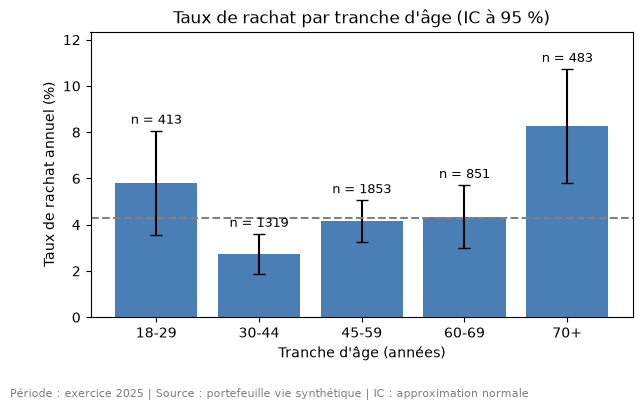

In [27]:
donnees = taux_age.drop("Non renseigné", errors="ignore")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(donnees.index.astype(str), donnees.taux_rachat * 100,
       yerr=donnees.ic95 * 100, capsize=4, color="#4a7fb5")

for i, ligne in enumerate(donnees.itertuples()):
    ax.text(i, (ligne.taux_rachat + ligne.ic95) * 100 + 0.3, f"n = {ligne.effectif}", ha="center", fontsize=9)

ax.axhline(taux_global * 100, linestyle="--", color="gray")
ax.set_xlabel("Tranche d'âge (années)")
ax.set_ylabel("Taux de rachat annuel (%)")
ax.set_title("Taux de rachat par tranche d'âge (IC à 95 %)")
ax.set_ylim(0, (donnees.taux_rachat + donnees.ic95).max() * 100 * 1.15)
fig.text(0.01, 0.01, "Période : exercice 2025 | Source : portefeuille vie synthétique | IC : approximation normale", fontsize=8, color="gray")
fig.subplots_adjust(bottom=0.2)
plt.show()